In [1]:

import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [3]:
df.corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


Text(0.5, 1.0, 'Feature Correlation Matrix')

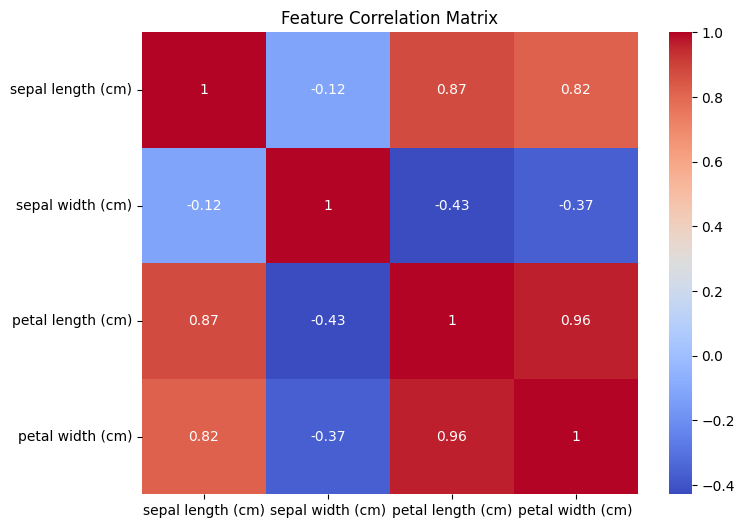

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Feature Correlation Matrix")

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1","PC2","PC3"])

pca_df.head()

,PC1,PC2,PC3
0,-2.264703,0.480027,0.127706
1,-2.080961,-0.674134,0.234609
2,-2.364229,-0.341908,-0.044201
3,-2.299384,-0.597395,-0.091290
4,-2.389842,0.646835,-0.015738


In [10]:
print(pca.explained_variance_ratio_)

[0.72962445 0.22850762 0.03668922]


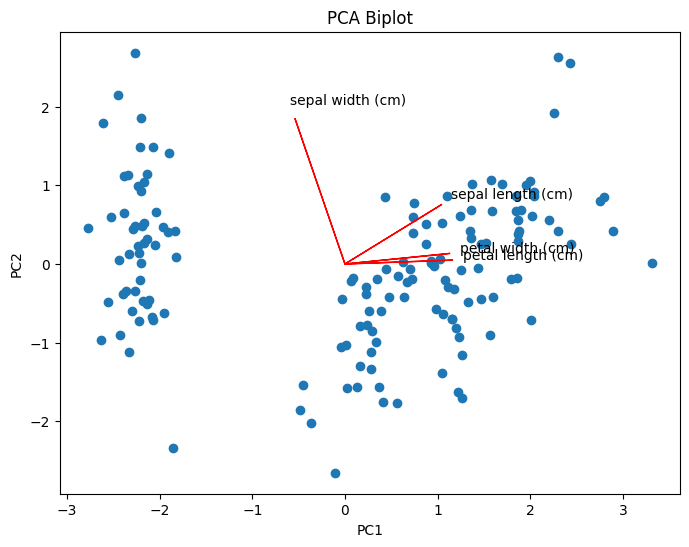

In [11]:
plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1])

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot")

for i, feature in enumerate(df.columns):
    plt.arrow(0,0,
              pca.components_[0,i]*2,
              pca.components_[1,i]*2,
              color='red')
    plt.text(pca.components_[0,i]*2.2,
             pca.components_[1,i]*2.2,
             feature)

plt.show()

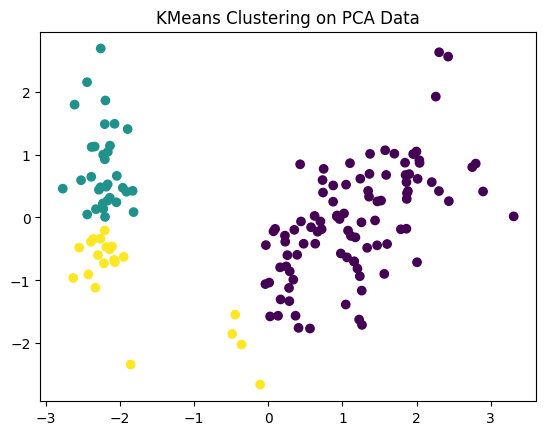

In [12]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)

kmeans_labels = kmeans.fit_predict(X_pca)

plt.scatter(X_pca[:,0], X_pca[:,1], c=kmeans_labels)

plt.title("KMeans Clustering on PCA Data")
plt.show()

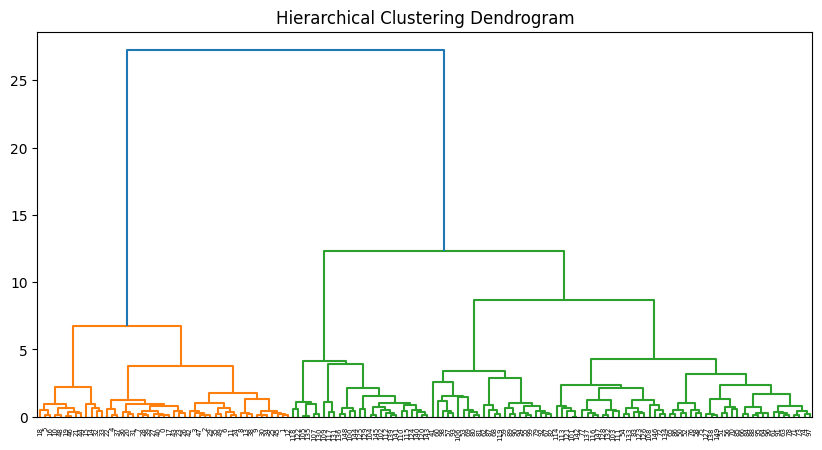

In [13]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_pca, method="ward")

plt.figure(figsize=(10,5))

dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")

plt.show()

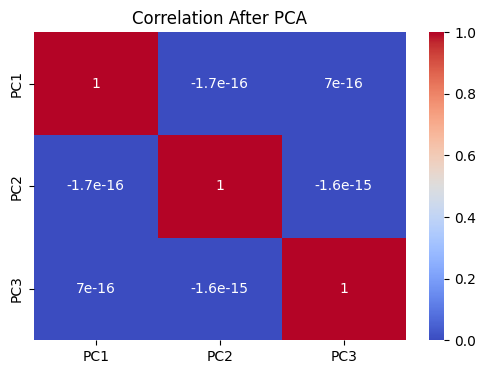

In [14]:
plt.figure(figsize=(6,4))

sns.heatmap(pca_df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation After PCA")

plt.show()

Original correlation plot:
Several features such as petal length and petal width show strong positive correlations, indicating redundancy in the dataset.

After PCA:
The transformed principal components show much lower correlations because PCA creates new orthogonal variables that remove redundancy.

Clustering results:
Both K-means and hierarchical clustering roughly identify the three natural groupings in the data, corresponding to the three Iris species.